# HAB 26–27 · E1

Cuaderno individual. Identificador de entrega: **sanchezdona_antonio**.

Cierre: **24/10/2026, 02:00 Europe/Madrid**.

Este es tu documento de trabajo: explicación, código, resultados, comprobaciones e interpretación. Desarrolla el análisis con la asistencia de IA que necesites y documenta tu juicio. No se entrega un informe adicional. Consulta la pregunta y los requisitos del análisis en TAREA_ANALISIS_FUNCIONAL.html.

## Cómo trabajar sin perder secciones

Guarda una copia personal en Drive (Archivo → Guardar una copia en Drive) o en tu ordenador. Añade celdas de texto y código **debajo** de cada encabezado; no conviertas una celda con marcador en código ni borres su encabezado. Conserva una sola aparición de cada uno de los seis marcadores `E1-…`. Puedes reordenar o ampliar tu trabajo dentro de cada sección.

La carga y los controles del paquete son la única implementación proporcionada; el análisis funcional lo desarrollas tú. Las celdas vacías se ejecutan sin producir resultados.

## Cargar los datos

**Panel Archivos:** sube `airway_26-27_v1.1.zip` y deja `USAR_DRIVE=False`. Tendrás que subirlo de nuevo si se reinicia o elimina la máquina de Colab.

**Drive:** guarda el ZIP en tu Drive, pon `USAR_DRIVE=True` y ajusta `RUTA_ZIP_DRIVE` a su ubicación. Montar Drive da acceso a archivos; guardar el cuaderno es un paso distinto. No necesitas instalar paquetes para esta carga. Para reproducir la entrega debe bastar el ZIP común y una configuración de ruta documentada.


In [1]:
from pathlib import Path
# Opción A (predeterminada): sube el ZIP al panel Archivos de Colab.
# En Jupyter local, sitúa el ZIP en el directorio de trabajo.
USAR_DRIVE = False
RUTA_ZIP_DRIVE = "/content/drive/MyDrive/HAB_26-27/airway_26-27_v1.1.zip"

if USAR_DRIVE:
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError("El montaje de Drive requiere Colab. En local, usa USAR_DRIVE=False.") from exc
    drive.mount("/content/drive")
    ZIP = Path(RUTA_ZIP_DRIVE)
else:
    ZIP = Path("airway_26-27_v1.1.zip")
if not ZIP.is_file():
    raise FileNotFoundError(f"No se encuentra {ZIP}. Sube el ZIP al panel Archivos o configura su ruta de Drive.")
print("Datos:", ZIP)


Datos: airway_26-27_v1.1.zip


In [2]:
import csv, json, hashlib, zipfile, io
# Integridad del paquete común. No selecciona genes ni resuelve el análisis.
with zipfile.ZipFile(ZIP) as z:
    manifests = [n for n in z.namelist() if n.endswith("/MANIFEST_SHA256.json") or n == "MANIFEST_SHA256.json"]
    if len(manifests) != 1:
        raise ValueError("El ZIP debe contener un manifiesto único.")
    prefix = manifests[0][:-len("MANIFEST_SHA256.json")]
    manifest_bytes = z.read(manifests[0])
    if hashlib.sha256(manifest_bytes).hexdigest() != "f78f1476a8bb0ea910d02ab996b027b600b024224d9bf41b7b4df9d7bded48e2":
        raise ValueError("El manifiesto no corresponde al paquete airway v1.1 del curso.")
    manifest = json.loads(manifest_bytes)
    for name, digest in manifest.items():
        if hashlib.sha256(z.read(prefix + name)).hexdigest() != digest:
            raise ValueError(f"Archivo dañado o modificado: {name}")
    de = list(csv.DictReader(io.StringIO(z.read(prefix + "expresion_diferencial.csv").decode("utf-8"))))
    samples = list(csv.DictReader(io.StringIO(z.read(prefix + "raw/samples.csv").decode("utf-8"))))
    gmt_text = z.read(prefix + "anotaciones/MSigDB_Hallmark_2020.gmt").decode("utf-8")
    diccionario = z.read(prefix + "DICCIONARIO.md").decode("utf-8")
    procedencia = json.loads(z.read(prefix + "procedencia.json"))
Path("MANIFEST_SHA256.json").write_bytes(manifest_bytes)
print({"filas_DE": len(de), "muestras": len(samples), "integridad": "hashes comprobados"})
print("Manifiesto para exportar el JSON:", Path("MANIFEST_SHA256.json").resolve())
# de y samples contienen texto CSV: convierte números, booleanos y ausencias.
# gmt_text contiene la colección; diccionario y procedencia documentan las entradas.
# Estas variables no incluyen universo, ranking ni análisis funcional resueltos.


{'filas_DE': 63677, 'muestras': 8, 'integridad': 'hashes comprobados'}
Manifiesto para exportar el JSON: /content/MANIFEST_SHA256.json


## E1-pregunta_datos

Formula una pregunta funcional para el contraste dexametasona frente a control. Describe signo, diseño pareado, unidad experimental y límites. Lee el diccionario y la procedencia. Audita ausencias, IDs, pérdidas y duplicados; distingue elegibilidad de selección por significación. Justifica tu universo y la regla de correspondencia con la colección.

Añade aquí tu explicación y las celdas necesarias.


### Pregunta

**¿Los genes que la dexametasona hace bajar en las células de músculo liso de vía aérea están sobrerrepresentados en programas Hallmark inflamatorios (Inflammatory Response y TNF-alpha Signaling via NF-kB), y qué programas aparecen entre los genes que hace subir?**

He planteado la pregunta así porque la dexametasona es un glucocorticoide y el estudio de origen (Himes et al., 2014) trata precisamente de genes que responden a glucocorticoides y modulan la función de citocinas. Mi hipótesis de partida, basada solo en eso, era que los conjuntos inflamatorios aparecerían entre los genes que bajan y no entre los que suben. Si no se cumple, habrá que revisar qué significa realmente cada etiqueta funcional.

### Datos, contraste y alcance

Los datos proceden del paquete docente `hab-airway-26-27-v1.1`, construido a partir de `airway 1.32.0` (Bioconductor; Himes et al., 2014; GEO GSE52778). La tabla de expresión diferencial se calculó con PyDESeq2 0.5.4 y el diseño `~cell + dex`, como se ve al imprimir `procedencia` en la celda siguiente. El contraste es dexametasona frente a control (`trt` frente a `untrt`) ajustado por línea celular, de modo que un `log2FoldChange` positivo significa más expresión con el tratamiento.

Según el apartado *ASM Cell Culture and GC Treatment for RNA-Seq Experiment* de Himes et al. (2014), se usaron células primarias de músculo liso de vía aérea (ASM) de cuatro donantes de pulmón para trasplante sin enfermedad crónica, tratadas con dexametasona 1 µM o con vehículo control durante 18 h. El artículo incluye otros experimentos con otras dosis y tiempos que no forman parte de estos datos.

La unidad experimental es, por tanto, la línea celular: hay 4 líneas con una muestra control y una tratada cada una, es decir, 4 pares y no 8 pacientes independientes. Por eso el modelo incluye `cell` y solo quedan 3 grados de libertad residuales (README del paquete). Lo que se concluya habla de cambios de ARN en células en cultivo de 4 donantes, no de actividad demostrada de una vía ni de efecto clínico. Tampoco se intenta reproducir las cifras del artículo, porque la tabla docente es un análisis derivado con su propia procedencia, ni se repiten la cuantificación o la expresión diferencial: el trabajo parte de `expresion_diferencial.csv` tal cual.

En las celdas siguientes se auditan los datos (ausencias, identificadores, duplicados y pérdidas) y después se define el universo.

In [3]:
# Instalación: en Google Colab no hace falta instalar nada, porque pandas, numpy, scipy,
# statsmodels y matplotlib ya vienen instalados. En un Jupyter local, antes de ejecutar:
#   pip install pandas numpy scipy statsmodels matplotlib
# (las versiones exactas usadas quedan impresas aquí y en la sección de reproducibilidad).
import math, sys, io, zipfile, hashlib, datetime, platform
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
from statsmodels.stats.multitest import multipletests
import matplotlib
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', 200)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.width', 200)

# Parámetros del análisis, todos en un mismo sitio
PARAMETROS = {
    'umbral_padj_gen': 0.05,        # FDR por gen (columna padj de la tabla) para seleccionar
    'umbral_abs_log2FC': 1.0,       # |log2FC| >= 1, es decir, al menos el doble o la mitad
    'alfa_funcional': 0.05,         # FDR (BH) sobre los contrastes funcionales
    'test': 'hipergeométrico unilateral (sobrerrepresentación)',
    'correccion': 'Benjamini-Hochberg conjunta sobre 50 conjuntos x 2 direcciones = 100 tests',
    'duplicados': 'por símbolo se conserva la fila con mayor baseMean (empate: menor gene_id)',
    'coleccion': 'MSigDB_Hallmark_2020 (snapshot del paquete, 50 conjuntos)',
}
print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| numpy', np.__version__,
      '| scipy', scipy.__version__, '| statsmodels', statsmodels.__version__, '| matplotlib', matplotlib.__version__)
for k, v in PARAMETROS.items():
    print(f'{k}: {v}')

Python 3.13.16 | pandas 2.2.3 | numpy 2.1.3 | scipy 1.16.3 | statsmodels 0.15.0 | matplotlib 3.10.0
umbral_padj_gen: 0.05
umbral_abs_log2FC: 1.0
alfa_funcional: 0.05
test: hipergeométrico unilateral (sobrerrepresentación)
correccion: Benjamini-Hochberg conjunta sobre 50 conjuntos x 2 direcciones = 100 tests
duplicados: por símbolo se conserva la fila con mayor baseMean (empate: menor gene_id)
coleccion: MSigDB_Hallmark_2020 (snapshot del paquete, 50 conjuntos)


In [4]:
# Procedencia y diseño: se leen del propio paquete en lugar de copiarlos a mano
campos = ['package_id', 'source_package', 'study_doi', 'geo', 'design', 'contrast', 'positive_effect',
          'prefilter', 'software', 'gene_p_adjustment', 'annotation', 'collection', 'rows', 'tested_rows']
for c in campos:
    print(f'{c}: {procedencia[c]}')

muestras = pd.DataFrame(samples).rename(columns={'': 'muestra'})
print()
print(muestras[['muestra', 'cell', 'dex', 'albut']].to_string(index=False))
print()
print('Muestras por línea celular y condición:')
print(pd.crosstab(muestras['cell'], muestras['dex']))
assert (pd.crosstab(muestras['cell'], muestras['dex']) == 1).all().all(), 'No hay exactamente un par por línea'

package_id: hab-airway-26-27-v1.1
source_package: airway 1.32.0
study_doi: 10.1371/journal.pone.0099625
geo: GSE52778
design: ~cell + dex
contrast: ['dex', 'trt', 'untrt']
positive_effect: dexamethasone > untreated
prefilter: counts >= 10 in >= 4 of 8 samples
software: PyDESeq2 0.5.4; Python 3.12.10; R 4.2.1 extraction
gene_p_adjustment: Benjamini-Hochberg over 16139 tested genes
annotation: Embedded airway annotation; Ensembl GRCh37 release 75 provenance; not current HGNC
collection: MSigDB_Hallmark_2020 (Enrichr snapshot; exact MSigDB release unspecified by endpoint)
rows: 63677
tested_rows: 16139

   muestra    cell   dex albut
SRR1039508  N61311 untrt untrt
SRR1039509  N61311   trt untrt
SRR1039512 N052611 untrt untrt
SRR1039513 N052611   trt untrt
SRR1039516 N080611 untrt untrt
SRR1039517 N080611   trt untrt
SRR1039520 N061011 untrt untrt
SRR1039521 N061011   trt untrt

Muestras por línea celular y condición:
dex      trt  untrt
cell               
N052611    1      1
N061011    1

#### Conversión explícita de la tabla y auditoría de ausencias

La carga deja la tabla como texto, así que convierto los números y los booleanos de forma explícita. Los campos vacíos pasan a ser ausentes (NaN) y nunca ceros, como pide el diccionario, y compruebo que esas ausencias coinciden exactamente con los genes que no pasaron el prefiltro.

In [5]:
tabla = pd.DataFrame(de)
NUMERICAS = ['baseMean', 'log2FoldChange', 'lfcSE', 'stat', 'pvalue', 'padj']

def a_numero(valor):
    # Vacío = ausente. Cualquier otro texto debe poder convertirse; si no, que falle.
    return np.nan if valor == '' else float(valor)

for col in NUMERICAS:
    tabla[col] = tabla[col].map(a_numero).astype(float)
assert set(tabla['prefilter_pass']) <= {'True', 'False'}, 'Valores booleanos inesperados'
tabla['prefilter_pass'] = tabla['prefilter_pass'].map({'True': True, 'False': False}).astype(bool)

print('Filas:', len(tabla), '| gene_id únicos:', tabla['gene_id'].is_unique)
print()
print('Filas por test_status:')
print(tabla['test_status'].value_counts().to_string())
print()
print('Valores ausentes por columna y estado:')
print(tabla.groupby('test_status')[NUMERICAS].apply(lambda d: d.isna().sum()))

probados = tabla['test_status'] == 'tested'
# Las ausencias solo deben estar en los genes de bajo recuento, y estos no deben tener ningún valor
assert tabla.loc[probados, NUMERICAS].notna().all().all()
assert tabla.loc[~probados, NUMERICAS].isna().all().all()
assert (tabla['prefilter_pass'] == probados).all(), 'prefilter_pass no coincide con test_status'
# El estadístico de Wald debe ser log2FC / lfcSE (mismo signo que log2FC)
t_ = tabla[probados]
print()
print('stat coincide con log2FC/lfcSE en todos los probados:',
      np.allclose(t_['stat'], t_['log2FoldChange'] / t_['lfcSE'], rtol=1e-7, atol=1e-9))

Filas: 63677 | gene_id únicos: True

Filas por test_status:
test_status
low_count    47538
tested       16139

Valores ausentes por columna y estado:
             baseMean  log2FoldChange  lfcSE   stat  pvalue   padj
test_status                                                       
low_count       47538           47538  47538  47538   47538  47538
tested              0               0      0      0       0      0

stat coincide con log2FC/lfcSE en todos los probados: True


#### Auditoría de identificadores

La colección Hallmark viene en símbolos de gen, mientras que la clave única de la tabla es el ID de Ensembl (`gene_id`). Hay que trabajar, por tanto, en espacio de símbolos y revisar tres cosas: símbolos vacíos, símbolos duplicados y símbolos de la colección que no aparecen en la anotación, que es histórica (Ensembl GRCh37 release 75).

In [6]:
# Colección: nombre, descripción (puede estar vacía) y símbolos
conjuntos = {}
for linea in gmt_text.splitlines():
    if not linea.strip():
        continue
    campos_gmt = linea.split('\t')
    genes = [g for g in campos_gmt[2:] if g]
    assert len(genes) == len(set(genes)), f'Símbolo repetido dentro de {campos_gmt[0]}'
    conjuntos[campos_gmt[0]] = set(genes)
simbolos_coleccion = set().union(*conjuntos.values())
tam = pd.Series({k: len(v) for k, v in conjuntos.items()})
print('Conjuntos:', len(conjuntos), '| símbolos distintos en la colección:', len(simbolos_coleccion))
print('Tamaño de los conjuntos: mínimo', tam.min(), '| mediana', tam.median(), '| máximo', tam.max())

# Símbolos de la tabla
print()
print('Símbolos vacíos en toda la tabla:', (tabla['symbol'] == '').sum())
print('symbol distinto de gene_name:', (tabla['symbol'] != tabla['gene_name']).sum())
solo_probados = tabla[probados]
dup = solo_probados[solo_probados['symbol'].duplicated(keep=False)].sort_values(['symbol', 'baseMean'], ascending=[True, False])
dup = dup.assign(en_hallmark=dup['symbol'].isin(simbolos_coleccion))
print('Genes probados con símbolo repetido:', len(dup), 'filas,', dup['symbol'].nunique(), 'símbolos')
print(dup[['gene_id', 'symbol', 'gene_biotype', 'baseMean', 'log2FoldChange', 'padj', 'en_hallmark']].to_string(index=False))

Conjuntos: 50 | símbolos distintos en la colección: 4383
Tamaño de los conjuntos: mínimo 32 | mediana 180.0 | máximo 200

Símbolos vacíos en toda la tabla: 0
symbol distinto de gene_name: 0
Genes probados con símbolo repetido: 29 filas, 12 símbolos
        gene_id   symbol         gene_biotype    baseMean  log2FoldChange     padj  en_hallmark
ENSG00000173207    CKS1B       protein_coding  196.109485       -0.288877 0.182647         True
ENSG00000268942    CKS1B       protein_coding   29.495390       -0.292653 0.649614         True
ENSG00000233280   CRYBG3       protein_coding  540.872671       -0.655814 0.000012        False
ENSG00000080200   CRYBG3       protein_coding  493.511058       -0.636073 0.000004        False
ENSG00000010404      IDS       protein_coding 1953.631228        0.186534 0.173752         True
ENSG00000241489      IDS       protein_coding   16.147406       -0.550801 0.454827         True
ENSG00000256977    LIMS3       protein_coding  176.367044       -0.242945 0.416

In [7]:
# Símbolos de la colección que no se encuentran en la anotación del paquete
todos_simbolos_tabla = set(tabla['symbol'])
simbolos_probados = set(tabla.loc[probados, 'symbol'])
ausentes_anotacion = sorted(simbolos_coleccion - todos_simbolos_tabla)
no_probados = sorted((simbolos_coleccion & todos_simbolos_tabla) - simbolos_probados)
print('Símbolos de Hallmark:', len(simbolos_coleccion))
print('  presentes entre los genes probados:', len(simbolos_coleccion & simbolos_probados))
print('  en la anotación pero no probados (bajo recuento):', len(no_probados))
print('  sin ninguna fila en la anotación:', len(ausentes_anotacion))
print()
print('Ejemplos sin fila en la anotación:', ', '.join(ausentes_anotacion[:40]), '...')

perdida_por_conjunto = pd.DataFrame({
    'tamaño_gmt': tam,
    'sin_fila_en_anotacion': {k: len(v - todos_simbolos_tabla) for k, v in conjuntos.items()},
}).sort_values('sin_fila_en_anotacion', ascending=False)
print()
print('Conjuntos que más símbolos pierden por no encontrarse en la anotación:')
print(perdida_por_conjunto.head(8).to_string())

# ¿Puede ser un problema de nombres antiguos? Se miran algunos símbolos que no están en Hallmark
# pero sí en la tabla, y que tienen pinta de ser los nombres antiguos de genes que sí están
print()
print('Filas de la tabla con símbolos que no están en Hallmark (posibles nombres antiguos):')
print(tabla.loc[tabla['symbol'].isin(['CYR61', 'CTGF', 'IL8']),
                ['gene_id', 'symbol', 'log2FoldChange', 'padj', 'test_status']].to_string(index=False))
for nuevo_nombre in ['CCN1', 'CCN2', 'CXCL8']:
    print(f'{nuevo_nombre} aparece en el GMT en:', ', '.join(k for k, v in conjuntos.items() if nuevo_nombre in v))

Símbolos de Hallmark: 4383
  presentes entre los genes probados: 3423
  en la anotación pero no probados (bajo recuento): 841
  sin ninguna fila en la anotación: 119

Ejemplos sin fila en la anotación: AARS1, ACKR1, ADGRA2, ADGRE1, ADGRG1, ADGRL2, ADGRL4, ATP5F1A, ATP5F1B, ATP5F1C, ATP5F1D, ATP5F1E, ATP5MC1, ATP5MC2, ATP5MC3, ATP5ME, ATP5MF, ATP5MG, ATP5PB, ATP5PD, ATP5PF, ATP5PO, CAVIN1, CAVIN2, CAVIN3, CCN1, CCN2, CCN5, CEP131, CNOT9, COQ8A, CRYBG1, CXCL8, DARS1, DENND2B, DMAC2L, DOP1A, EEF1AKMT1, ELOA, ELP1 ...

Conjuntos que más símbolos pierden por no encontrarse en la anotación:
                           tamaño_gmt  sin_fila_en_anotacion
Oxidative Phosphorylation         200                     16
G2-M Checkpoint                   200                     10
Hypoxia                           200                      9
Adipogenesis                      200                      8
p53 Pathway                       200                      8
heme Metabolism                   200     

#### Decisiones sobre identificadores

Entre los genes probados hay 12 símbolos repetidos (29 filas), y 3 de ellos están en Hallmark (CKS1B, IDS y SRSF10). Para cada símbolo conservo la fila de mayor `baseMean` y, si hay empate, la de `gene_id` menor. Es una regla que no depende de la significación, como pide el diccionario; elegir la fila con menor `padj` habría metido un sesgo a favor de encontrar genes seleccionados. Sumar o promediar filas queda descartado porque los estadísticos de PyDESeq2 no se pueden combinar así sin rehacer el modelo.

Otro problema son los 119 símbolos de Hallmark que no tienen ninguna fila en la tabla. Muchos parecen nombres actualizados de genes que la anotación de 2014 llama de otra forma: en la tabla aparecen CYR61, CTGF e IL8, que no están en el GMT, mientras que en el GMT aparecen CCN1, CCN2 y CXCL8. He decidido no renombrarlos, porque el paquete no trae ninguna tabla de equivalencias versionada y hacerlo a mano, gen a gen, sería poco reproducible y fácil de equivocar. Queda como una pérdida documentada (alrededor del 2,7 % de los símbolos de la colección) y como algo que comprobar en E2, ya que dos de esos casos (CYR61 y CTGF) sí cambian con el tratamiento en la tabla, mientras que IL8 no cambia.

Por último, universo, listas seleccionadas y conjuntos se comparan siempre en el mismo espacio: símbolos de la tabla después de quitar duplicados.

#### Universo

Sigo la aclaración de la guía de lecturas (versión 2): el universo es la lista de genes con datos suficientes y resultados válidos para aplicar el criterio de selección, e incluye tanto los que salen seleccionados como los que no. Un gen descartado antes por falta de expresión no pertenece al universo, y Hallmark aporta los conjuntos que se contrastan, pero no define el universo. Es la misma idea que da la documentación de GO, según la cual la referencia deben ser los genes que podían haber salido seleccionados en el experimento.

Con ese criterio, el universo lo forman los genes que cumplen todo esto:

- `test_status == tested` (pasaron el prefiltro de 10 recuentos en al menos 4 muestras y tienen test), con `pvalue`, `padj` y `log2FoldChange` finitos;
- símbolo no vacío (los conjuntos vienen en símbolos), con una sola fila por símbolo según la regla de duplicados.

No uso todo el genoma (63.677 filas), porque unos 47.500 genes tienen tan pocos recuentos que nunca podían salir seleccionados, ni solo los genes significativos, que dejarían el test sin referencia. Ningún paso del universo usa `padj` ni el signo del cambio. La celda siguiente indica cuántos genes quedan en cada paso y cuántos pertenecen a algún conjunto Hallmark; esa misma referencia se usa en todo el cálculo.

In [8]:
# Construcción del universo, contando las pérdidas paso a paso
pasos = []
u = tabla.copy()
pasos.append(('Filas de la tabla', len(u), u['symbol'].nunique()))
u = u[u['test_status'] == 'tested']
pasos.append(('test_status == tested', len(u), u['symbol'].nunique()))
u = u[np.isfinite(u['pvalue']) & np.isfinite(u['padj']) & np.isfinite(u['log2FoldChange'])]
pasos.append(('p, padj y log2FC finitos', len(u), u['symbol'].nunique()))
u = u[u['symbol'] != '']
pasos.append(('símbolo no vacío', len(u), u['symbol'].nunique()))
u = (u.sort_values(['symbol', 'baseMean', 'gene_id'], ascending=[True, False, True])
       .drop_duplicates('symbol', keep='first'))
pasos.append(('una fila por símbolo (mayor baseMean)', len(u), u['symbol'].nunique()))
genes_probados_unicos = u.copy()
universo = u.set_index('symbol')

print(pd.DataFrame(pasos, columns=['paso', 'filas', 'símbolos únicos']).to_string(index=False))
print()
print('Filas de símbolos duplicados que se conservan y que están en Hallmark:')
print(dup[dup['en_hallmark']].drop_duplicates('symbol')[['symbol', 'gene_id', 'baseMean']].to_string(index=False))
assert universo.index.is_unique
print()
print('Tamaño del universo N =', len(universo))
print('De ellos, con símbolo en al menos un conjunto Hallmark:', universo.index.isin(list(simbolos_coleccion)).sum(),
      '| sin ningún conjunto (siguen en el universo como genes no anotados):', (~universo.index.isin(list(simbolos_coleccion))).sum())

                                 paso  filas  símbolos únicos
                    Filas de la tabla  63677            56638
                test_status == tested  16139            16122
             p, padj y log2FC finitos  16139            16122
                     símbolo no vacío  16139            16122
una fila por símbolo (mayor baseMean)  16122            16122

Filas de símbolos duplicados que se conservan y que están en Hallmark:
symbol         gene_id    baseMean
 CKS1B ENSG00000173207  196.109485
   IDS ENSG00000010404 1953.631228
SRSF10 ENSG00000188529 1446.494153

Tamaño del universo N = 16122
De ellos, con símbolo en al menos un conjunto Hallmark: 3423 | sin ningún conjunto (siguen en el universo como genes no anotados): 12699


## E1-metodo

Justifica universo, umbral, dirección, colección y familia de tests. Desarrolla ORA con ajuste múltiple explícito. Conserva tabla completa de conjuntos evaluados, parámetros, recuentos N/K/n/k y genes del solapamiento; incluye las figuras que ayuden a responder tu pregunta. Explica una alternativa metodológica descartada. No hay un umbral ni número de resultados significativos obligatorios.

Añade aquí tu explicación y las celdas necesarias.


### Decisiones del método y por qué

#### Selección de genes

Un gen se selecciona si tiene `padj < 0.05` y `|log2FC| >= 1`, es decir, al menos el doble o la mitad de expresión. Uso el `padj` de la tabla (FDR por gen) y nunca el p sin ajustar. El umbral de efecto lo añado porque, con solo 4 pares, prefiero quedarme con cambios claros y no con diferencias pequeñas que salen significativas por tener mucha expresión. Es un corte arbitrario, y de hecho en las diapositivas de T3.d se propone uno más laxo (`P < 0,1` y `|FC| > 1,25`) para análisis funcionales exploratorios; por eso el cambio de umbral es una de las cosas que pienso poner a prueba en E2.

#### Dirección del cambio

Los genes que suben y los que bajan se analizan por separado. Un glucocorticoide activa unos genes y reprime otros, y al mezclar las dos listas un conjunto podría salir enriquecido por genes que van en sentidos contrarios sin que se supiera qué significa. Además, la pregunta es direccional.

#### Colección

Se usa el snapshot `MSigDB_Hallmark_2020` del paquete (50 conjuntos), sin cambiarlo. Hallmark se construyó para reducir la redundancia y la heterogeneidad de las colecciones grandes (Liberzon et al., 2015), lo que viene bien para una primera interpretación con pocos tests. Aun así, reducir la redundancia no hace que los conjuntos sean independientes, porque pueden compartir genes, y por eso la interpretación vuelve a los genes que sostienen cada resultado. Otra limitación es su poca resolución: no hay un conjunto específico de respuesta a glucocorticoides.

#### Test y corrección múltiple

Para cada conjunto y dirección aplico un test hipergeométrico unilateral (equivalente al test exacto de Fisher unilateral), ya que solo interesa la sobrerrepresentación. Como son 50 conjuntos por 2 direcciones, Benjamini-Hochberg se aplica una sola vez sobre los 100 p-valores juntos y no por separado en cada dirección, que permitiría el doble de falsos positivos esperados. Se considera significativo `q < 0.05`. Los 50 conjuntos se evalúan sin filtrar por tamaño, porque el más pequeño conserva 19 genes en el universo (lo imprime la celda de abajo), que me parece suficiente para este test.

#### Notación

En la tabla de resultados, N es el número de genes del universo, K los genes del conjunto que están en el universo, n los genes seleccionados en esa dirección y k los seleccionados que están en el conjunto. El p-valor es P(X >= k) con X ~ Hipergeométrica(N, K, n), o sea, la probabilidad de ver un solapamiento igual o mayor que el observado y no solo el valor exacto. Como medida de tamaño se da el fold enrichment = (k/n)/(K/N), que compara proporciones. No es una odds ratio, que compara odds, aunque a veces se confundan (lo advierte la guía al comentar Bora et al., 2026).

In [9]:
seleccion = {
    'sube': set(universo.index[(universo['padj'] < PARAMETROS['umbral_padj_gen']) &
                               (universo['log2FoldChange'] >= PARAMETROS['umbral_abs_log2FC'])]),
    'baja': set(universo.index[(universo['padj'] < PARAMETROS['umbral_padj_gen']) &
                               (universo['log2FoldChange'] <= -PARAMETROS['umbral_abs_log2FC'])]),
}
for d, s in seleccion.items():
    print(f'Seleccionados que {d}n: n = {len(s)}')
print('Proporción seleccionada del universo:', round((len(seleccion['sube']) + len(seleccion['baja'])) / len(universo), 3))

Seleccionados que suben: n = 493
Seleccionados que bajan: n = 464
Proporción seleccionada del universo: 0.059


In [10]:
def bh(pvalores):
    # Benjamini-Hochberg programado a mano (se comprueba con statsmodels en la verificación)
    p = np.asarray(pvalores, dtype=float)
    m = len(p)
    orden = np.argsort(p)
    ajust = p[orden] * m / np.arange(1, m + 1)
    ajust = np.minimum.accumulate(ajust[::-1])[::-1]
    q = np.empty(m)
    q[orden] = np.minimum(ajust, 1.0)
    return q


def ora(universo_simbolos, seleccion_por_direccion, conjuntos, lfc):
    U = set(universo_simbolos)
    N = len(U)
    filas = []
    for direccion, sel in seleccion_por_direccion.items():
        sel = set(sel) & U
        n = len(sel)
        for nombre, genes in conjuntos.items():
            enU = genes & U
            K = len(enU)
            sol = sorted(enU & sel, key=lambda g: -abs(lfc[g]))
            k = len(sol)
            p = stats.hypergeom.sf(k - 1, N, K, n)   # P(X >= k)
            filas.append({'direccion': direccion, 'conjunto': nombre, 'N': N, 'K': K, 'n': n, 'k': k,
                          'esperado': K * n / N, 'fold_enrichment': (k / n) / (K / N) if n and K else np.nan,
                          'p': p, 'genes_solapamiento': ', '.join(f'{g}({lfc[g]:+.2f})' for g in sol)})
    res = pd.DataFrame(filas)
    res['q_BH'] = bh(res['p'])
    return res.sort_values(['p', 'direccion', 'conjunto']).reset_index(drop=True)


lfc = universo['log2FoldChange']
resultados = ora(universo.index, seleccion, conjuntos, lfc)
resultados['significativo'] = resultados['q_BH'] < PARAMETROS['alfa_funcional']
print('Tests realizados:', len(resultados), '| K mínimo en el universo:', resultados['K'].min(),
      '| K máximo:', resultados['K'].max())
print('Significativos (q < 0.05):', resultados['significativo'].sum())

Tests realizados: 100 | K mínimo en el universo: 19 | K máximo: 195
Significativos (q < 0.05): 25


#### Tabla completa de los 100 tests

La tabla conserva todos los conjuntos evaluados, también los no significativos. En la columna `genes_solapamiento` aparecen los genes que sostienen cada resultado, con su log2FC entre paréntesis y ordenados por tamaño del cambio. Con N, K, n y k se puede rehacer cualquier p-valor, y la misma tabla, con los p a precisión completa, se guarda en `resultados/E1_ORA_hallmark_completa.csv`.

In [11]:
from pathlib import Path
Path('resultados').mkdir(exist_ok=True)
resultados.to_csv('resultados/E1_ORA_hallmark_completa.csv', index=False, float_format='%.17g')
# Universo y selección, para poder rehacer el cálculo fuera del cuaderno
(universo.reset_index()[['symbol', 'gene_id', 'baseMean', 'log2FoldChange', 'padj']]
 .assign(seleccion=lambda d: np.where(d['symbol'].isin(seleccion['sube']), 'sube',
                                      np.where(d['symbol'].isin(seleccion['baja']), 'baja', '')))
 .to_csv('resultados/E1_universo_y_seleccion.csv', index=False, float_format='%.17g'))

vista = resultados.copy()
vista['p'] = vista['p'].map(lambda x: f'{x:.3e}')
vista['q_BH'] = vista['q_BH'].map(lambda x: f'{x:.3e}')
vista['esperado'] = vista['esperado'].round(2)
vista['fold_enrichment'] = vista['fold_enrichment'].round(2)
vista[['direccion', 'conjunto', 'N', 'K', 'n', 'k', 'esperado', 'fold_enrichment', 'p', 'q_BH', 'significativo',
       'genes_solapamiento']]

,direccion,conjunto,N,K,n,k,esperado,fold_enrichment,p,q_BH,significativo,genes_solapamiento
0,sube,TNF-alpha Signaling via NF-kB,16122,172,493,26,5.26,4.94,1.561e-11,1.561e-09,True,"PER1(+3.19), DUSP1(+2.94), PTX3(+2.26), IRS2(+2.12), KLF9(+2.08), NR4A3(+2.07), ATF3(+1.92), PDLIM5(+1.60), GCH1(+1...."
1,baja,p53 Pathway,16122,177,464,21,5.09,4.12,4.050e-08,2.025e-06,True,"LIF(-2.60), TNFSF9(-1.86), FGF13(-1.56), RRAD(-1.50), CDKN2B(-1.43), HSPA4L(-1.33), IER3(-1.30), RAP2B(-1.28), HMOX1..."
2,baja,Epithelial Mesenchymal Transition,16122,191,464,18,5.50,3.27,1.056e-05,3.519e-04,True,"VCAM1(-3.69), LRRC15(-2.55), CXCL12(-1.92), MEST(-1.87), ADAM12(-1.82), TNFRSF11B(-1.64), POSTN(-1.42), MXRA5(-1.33)..."
3,sube,Epithelial Mesenchymal Transition,16122,191,493,18,5.84,3.08,2.377e-05,5.943e-04,True,"FZD8(+2.48), COL11A1(+2.42), PTX3(+2.26), IGFBP2(+2.21), NNMT(+2.18), LAMA2(+2.03), FBN2(+1.92), THBS1(+1.88), OXTR(..."
4,baja,KRAS Signaling Up,16122,134,464,14,3.86,3.63,3.215e-05,6.429e-04,True,"G0S2(-2.67), LIF(-2.60), MAFB(-1.92), GADD45G(-1.88), EPHB2(-1.77), PRKG2(-1.70), PTGS2(-1.36), SOX9(-1.33), NGF(-1...."
5,sube,Hypoxia,16122,164,493,16,5.02,3.19,4.392e-05,7.320e-04,True,"DUSP1(+2.94), ERRFI1(+2.42), MT1E(+2.22), MT2A(+2.21), IRS2(+2.12), STC1(+1.97), ATF3(+1.92), CITED2(+1.55), MAFF(+1..."
6,baja,Inflammatory Response,16122,125,464,13,3.60,3.61,6.421e-05,9.172e-04,True,"CCL7(-3.08), TNFSF15(-2.69), LIF(-2.60), TNFAIP6(-2.57), P2RX7(-1.98), BDKRB1(-1.87), TNFSF9(-1.86), ICOSLG(-1.63), ..."
7,baja,TNF-alpha Signaling via NF-kB,16122,172,464,15,4.95,3.03,1.372e-04,1.715e-03,True,"EGR2(-3.07), G0S2(-2.67), LIF(-2.60), TNFAIP6(-2.57), TNFSF9(-1.86), EGR3(-1.74), ICOSLG(-1.63), PTGS2(-1.36), IER3(..."
8,sube,KRAS Signaling Up,16122,134,493,13,4.10,3.17,2.377e-04,2.641e-03,True,"SPARCL1(+4.57), SPON1(+1.91), GPRC5B(+1.75), MMD(+1.68), HSD11B1(+1.56), SERPINA3(+1.38), TMEM100(+1.33), BTC(+1.30)..."
9,sube,Xenobiotic Metabolism,16122,149,493,13,4.56,2.85,6.642e-04,6.642e-03,True,"MAOA(+3.35), PDK4(+2.64), MT2A(+2.21), SPINT2(+2.10), DCXR(+2.09), PDLIM5(+1.60), GCH1(+1.60), HSD11B1(+1.56), AOX1(..."


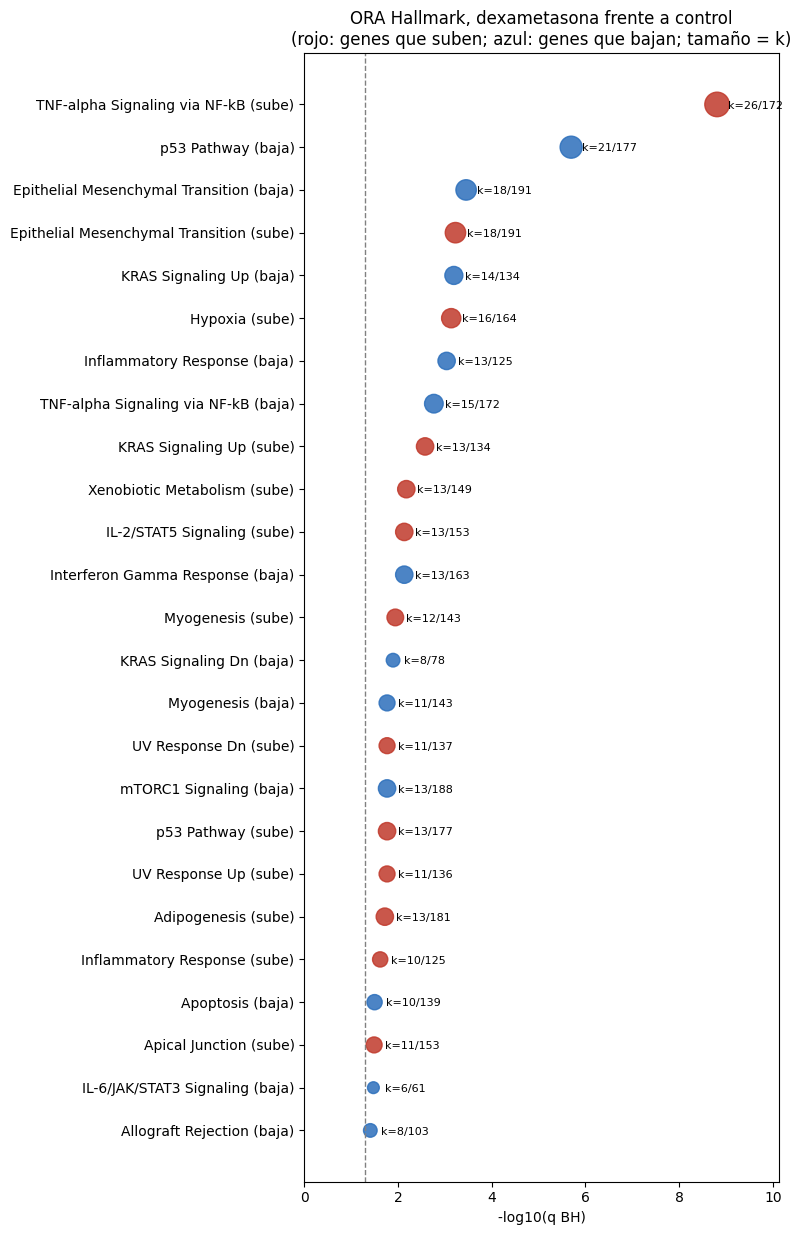

In [12]:
# Figura: conjuntos significativos (q < 0.05); la línea discontinua marca q = 0.05
fig_datos = resultados[resultados['q_BH'] < 0.05].copy()
fig_datos['etiqueta'] = fig_datos['conjunto'] + ' (' + fig_datos['direccion'] + ')'
fig_datos = fig_datos.sort_values('q_BH', ascending=False)
colores = fig_datos['direccion'].map({'sube': '#c0392b', 'baja': '#2c6fbb'})
fig, ax = plt.subplots(figsize=(8, 0.45 * len(fig_datos) + 1.2))
ax.scatter(-np.log10(fig_datos['q_BH']), fig_datos['etiqueta'], s=fig_datos['k'] * 12, c=colores, alpha=0.85)
for _, f in fig_datos.iterrows():
    ax.annotate(f"k={f['k']}/{f['K']}", (-np.log10(f['q_BH']), f['etiqueta']), xytext=(8, -3),
                textcoords='offset points', fontsize=8)
ax.axvline(-np.log10(0.05), color='grey', linestyle='--', linewidth=1)
ax.set_xlim(0, (-np.log10(fig_datos['q_BH'])).max() * 1.15)
ax.set_xlabel('-log10(q BH)')
ax.set_title('ORA Hallmark, dexametasona frente a control\n(rojo: genes que suben; azul: genes que bajan; tamaño = k)')
plt.tight_layout()
plt.savefig('resultados/E1_figura_ORA.png', dpi=150)
plt.show()

#### Alternativa metodológica descartada: restringir el universo a los genes anotados en Hallmark

Al principio me planteé usar como universo solo los genes probados que están en algún conjunto Hallmark, con el argumento de que un gen sin ningún conjunto nunca puede estar en un solapamiento pero sí hace más grande N. Al final la descarté por tres motivos. El primero es que la guía de lecturas (versión 2) aclara que el universo se construye con los genes evaluables y que Hallmark no lo define, de modo que restringirlo cambiaría la pregunta a "entre los genes que Hallmark conoce", que no es la planteada. El segundo es que Hallmark solo tiene 50 conjuntos y no cubre la mayoría del genoma: genes muy cambiados como KLF15 o CRISPLD2 dejarían de contar incluso como "seleccionados fuera de los conjuntos", y la proporción de seleccionados se calcularía sobre una parte muy particular de los genes. Y el tercero es que habría que justificar que los genes anotados se comportan como el resto, algo que aquí no se puede comprobar.

Para que la decisión quede a la vista, la celda siguiente rehace el ORA cambiando solo el universo y compara. Sirve para valorar cuánto depende el resultado de esta decisión, no para interpretar. Tampoco se usa todo el genoma, por lo explicado en la sección anterior, y los métodos con la lista ordenada completa (GSEA) quedan para E2.

In [13]:
anotados = universo[universo.index.isin(list(simbolos_coleccion))]
sel_alt = {d: s & set(anotados.index) for d, s in seleccion.items()}
alt = ora(anotados.index, sel_alt, conjuntos, anotados['log2FoldChange'])
comp = resultados.merge(alt, on=['direccion', 'conjunto'], suffixes=('_elegido', '_anotados'))
print('Universo elegido N =', resultados['N'].iloc[0], '| universo restringido a anotados N =', alt['N'].iloc[0])
print('n (sube/baja): elegido', len(seleccion['sube']), '/', len(seleccion['baja']),
      '| restringido', len(sel_alt['sube']), '/', len(sel_alt['baja']))
print('Significativos con q < 0.05: universo elegido', (resultados['q_BH'] < 0.05).sum(),
      '| restringido a anotados', (alt['q_BH'] < 0.05).sum())
sig_alt = set(zip(alt.loc[alt['q_BH'] < 0.05, 'direccion'], alt.loc[alt['q_BH'] < 0.05, 'conjunto']))
sig_ele = set(zip(resultados.loc[resultados['q_BH'] < 0.05, 'direccion'], resultados.loc[resultados['q_BH'] < 0.05, 'conjunto']))
print('¿Todos los significativos con el universo restringido lo son también con el elegido?', sig_alt <= sig_ele)
cols = ['direccion', 'conjunto', 'k_elegido', 'fold_enrichment_elegido', 'q_BH_elegido', 'fold_enrichment_anotados', 'q_BH_anotados']
print(comp.sort_values('q_BH_elegido')[cols].head(25).to_string(index=False, float_format=lambda x: f'{x:.3g}'))

Universo elegido N = 16122 | universo restringido a anotados N = 3423
n (sube/baja): elegido 493 / 464 | restringido 170 / 137
Significativos con q < 0.05: universo elegido 25 | restringido a anotados 5
¿Todos los significativos con el universo restringido lo son también con el elegido? True
direccion                          conjunto  k_elegido  fold_enrichment_elegido  q_BH_elegido  fold_enrichment_anotados  q_BH_anotados
     sube     TNF-alpha Signaling via NF-kB         26                     4.94      1.56e-09                      3.04        1.7e-05
     baja                       p53 Pathway         21                     4.12      2.02e-06                      2.96       0.000228
     baja Epithelial Mesenchymal Transition         18                     3.27      0.000352                      2.35          0.016
     sube Epithelial Mesenchymal Transition         18                     3.08      0.000594                       1.9         0.0817
     baja                 KRAS S

## E1-verificacion

Reconstruye al menos un cálculo mediante una comprobación independiente de la salida principal, por ejemplo tabla 2×2 y Fisher/hipergeométrica. Comprueba además una condición de integridad que pueda invalidar el análisis. Muestra resultados reales, qué error detectaría cada prueba y qué no demuestra. La comprobación de hashes de la carga no sustituye estas verificaciones.

Añade aquí tu explicación y las celdas necesarias.


La verificación consta de tres comprobaciones, cada una pensada para detectar un tipo de error distinto.

La primera es una reconstrucción independiente de un resultado mediante su tabla 2x2 y el test unilateral. Se vuelven a contar los genes desde la tabla original, sin usar la función `ora` ni el objeto `universo`, y el p se calcula con dos métodos distintos al principal: el test exacto de Fisher de scipy y una suma exacta con combinatoria en Python puro.

La segunda compara mi función de Benjamini-Hochberg con la de statsmodels.

La tercera es una comprobación de integridad del signo del contraste, que invalidaría todo el análisis por direcciones si estuviera al revés. A partir de los recuentos crudos (`raw/counts.csv`) y de las etiquetas de `raw/samples.csv` se recalcula un cambio de expresión muy simple y se mira si su signo coincide con el `log2FoldChange` de la tabla. En la misma celda se comprueba la coherencia de los espacios de IDs (selección dentro del universo, conjuntos recortados al universo, sin duplicados).

In [14]:
# 1) Reconstrucción independiente del resultado con menor p
fila = resultados.iloc[0]
conj, direc = fila['conjunto'], fila['direccion']
print('Resultado que se reconstruye:', conj, '|', direc)

# Se cuenta de nuevo desde la tabla original, repitiendo las reglas de forma independiente
t2 = tabla[(tabla['test_status'] == 'tested') & (tabla['symbol'] != '')].copy()
t2 = t2.sort_values('baseMean', ascending=False).groupby('symbol', as_index=False).first()
if direc == 'sube':
    t2['sel'] = (t2['padj'] < 0.05) & (t2['log2FoldChange'] >= 1)
else:
    t2['sel'] = (t2['padj'] < 0.05) & (t2['log2FoldChange'] <= -1)
t2['en_conj'] = t2['symbol'].isin(conjuntos[conj])
a = int((t2['sel'] & t2['en_conj']).sum())      # seleccionados dentro del conjunto (k)
b = int((t2['sel'] & ~t2['en_conj']).sum())     # seleccionados fuera del conjunto
c = int((~t2['sel'] & t2['en_conj']).sum())     # no seleccionados dentro del conjunto
d = int((~t2['sel'] & ~t2['en_conj']).sum())    # no seleccionados fuera del conjunto
tabla2x2 = pd.DataFrame([[a, b], [c, d]], index=['seleccionado', 'no seleccionado'],
                        columns=['en el conjunto', 'fuera del conjunto'])
print(tabla2x2)
p_fisher = stats.fisher_exact([[a, b], [c, d]], alternative='greater').pvalue

# Suma exacta de la cola hipergeométrica con enteros (Python puro, sin scipy)
N2, K2, n2 = a + b + c + d, a + c, a + b
p_comb = sum(math.comb(K2, i) * math.comb(N2 - K2, n2 - i) for i in range(a, min(K2, n2) + 1)) / math.comb(N2, n2)

print(f"\nPrincipal: N={fila['N']} K={fila['K']} n={fila['n']} k={fila['k']} p={fila['p']:.6e}")
print(f'Reconstrucción: N={N2} K={K2} n={n2} k={a} | Fisher unilateral p={p_fisher:.6e} | combinatoria p={p_comb:.6e}')
assert (N2, K2, n2, a) == (fila['N'], fila['K'], fila['n'], fila['k'])
assert math.isclose(p_fisher, fila['p'], rel_tol=1e-9) and math.isclose(p_comb, fila['p'], rel_tol=1e-9)
print('OK: los recuentos y el p coinciden con la salida principal.')

Resultado que se reconstruye: TNF-alpha Signaling via NF-kB | sube
                 en el conjunto  fuera del conjunto
seleccionado                 26                 467
no seleccionado             146               15483

Principal: N=16122 K=172 n=493 k=26 p=1.560727e-11
Reconstrucción: N=16122 K=172 n=493 k=26 | Fisher unilateral p=1.560727e-11 | combinatoria p=1.560727e-11
OK: los recuentos y el p coinciden con la salida principal.


In [15]:
# 2) Benjamini-Hochberg: función propia frente a statsmodels, sobre los mismos 100 p
q_sm = multipletests(resultados['p'], method='fdr_bh')[1]
dif = np.max(np.abs(q_sm - resultados['q_BH']))
print('Diferencia máxima entre q propios y q de statsmodels:', dif)
assert dif < 1e-12
# Si se corrigiera cada dirección por separado, ¿cambiaría algo?
q_sep = resultados.groupby('direccion')['p'].transform(lambda p: pd.Series(bh(p), index=p.index))
print('Significativos con BH conjunta (100 tests):', (resultados['q_BH'] < 0.05).sum(),
      '| con BH separada por dirección (2 x 50):', (q_sep < 0.05).sum())

Diferencia máxima entre q propios y q de statsmodels: 1.1102230246251565e-16
Significativos con BH conjunta (100 tests): 25 | con BH separada por dirección (2 x 50): 25


In [16]:
# 3) Integridad: signo del contraste a partir de los recuentos crudos del mismo ZIP (hash ya comprobado)
with zipfile.ZipFile(ZIP) as z:
    nombre_counts = [x for x in z.namelist() if x.endswith('raw/counts.csv')][0]
    recuentos = pd.read_csv(io.BytesIO(z.read(nombre_counts)), index_col=0)
assert list(recuentos.columns) == list(muestras['muestra'])
cpm = recuentos / recuentos.sum() * 1e6
log_cpm = np.log2(cpm + 1)
m = muestras.set_index('muestra')

def concordancia(etiquetas_trt):
    # Porcentaje de genes seleccionados (todos los probados) cuyo signo coincide con el cálculo crudo
    sel_ids = tabla.loc[(tabla['padj'] < 0.05) & (tabla['log2FoldChange'].abs() >= 1), ['gene_id', 'log2FoldChange']]
    trt = [s for s in m.index if etiquetas_trt[s] == 'trt']
    unt = [s for s in m.index if etiquetas_trt[s] == 'untrt']
    pares = []
    for c in m['cell'].unique():
        st = [s for s in trt if m.loc[s, 'cell'] == c][0]
        su = [s for s in unt if m.loc[s, 'cell'] == c][0]
        pares.append(log_cpm[st] - log_cpm[su])
    crudo = pd.concat(pares, axis=1).mean(axis=1).loc[sel_ids['gene_id']]
    return np.mean(np.sign(crudo.values) == np.sign(sel_ids['log2FoldChange'].values)), len(sel_ids)

conc, nsel = concordancia(m['dex'])
print(f'Genes con padj < 0.05 y |log2FC| >= 1: {nsel}. Signo igual al cálculo con recuentos crudos: {conc:.1%}')
# Control de que la prueba detectaría el fallo: se invierten las etiquetas trt/untrt
conc_inv, _ = concordancia(m['dex'].map({'trt': 'untrt', 'untrt': 'trt'}))
print(f'Con las etiquetas invertidas a propósito, la concordancia sería: {conc_inv:.1%}')
assert conc > 0.95, 'El signo del contraste no coincide con los recuentos: análisis por direcciones inválido'

# Coherencia de los espacios de identificadores
U = set(universo.index)
assert seleccion['sube'] <= U and seleccion['baja'] <= U and not (seleccion['sube'] & seleccion['baja'])
assert all(r.K == len(conjuntos[r.conjunto] & U) and r.k <= min(r.K, r.n) for r in resultados.itertuples())
assert universo[['pvalue', 'padj', 'log2FoldChange']].notna().all().all()
print('OK: selección dentro del universo, sin genes en las dos direcciones, K recalculado y sin ausentes.')

Genes con padj < 0.05 y |log2FC| >= 1: 957. Signo igual al cálculo con recuentos crudos: 100.0%
Con las etiquetas invertidas a propósito, la concordancia sería: 0.0%
OK: selección dentro del universo, sin genes en las dos direcciones, K recalculado y sin ausentes.


#### Qué demuestran estas pruebas y qué no

La reconstrucción 2x2 confirma que, para ese conjunto, los recuentos N, K, n y k y el p unilateral son correctos, y que la función `ora` usa bien la cola (P(X >= k) y no P(X > k), un error típico de desplazamiento en uno). Detectaría errores de conteo, de dirección de la cola o de cruce de identificadores. No demuestra que el resto de filas estén bien, aunque usan el mismo código, ni que el universo elegido sea el adecuado, porque eso es una decisión y no un cálculo.

La comparación de BH detecta errores en mi implementación del ajuste. También muestra que, en estos datos, corregir cada dirección por separado da el mismo número de significativos (25), así que esa decisión no cambia las conclusiones; aun así mantengo la corrección conjunta porque es la que corresponde a la familia de 100 tests declarada. Lo que no dice es si los tests son independientes, una suposición de ORA que no se cumple del todo porque los conjuntos comparten genes.

En cuanto a la prueba de signo, detectaría un contraste invertido (control frente a tratamiento) o etiquetas de muestras cambiadas, que darían la vuelta a todas las conclusiones de "sube" y "baja". Que sirve para eso se ve al invertir las etiquetas a propósito, porque la concordancia se hunde. No comprueba, en cambio, la calidad del modelo de expresión diferencial (dispersión, valores extremos), ya que el cálculo crudo es mucho más simple que PyDESeq2.

Ninguna de estas pruebas corrige los sesgos de ORA, como que los genes más expresados o más largos tengan más facilidad para salir significativos (Young et al., 2010).

## E1-interpretacion

Redacta dos o tres conclusiones funcionales, o explica por qué la evidencia no permite sostenerlas. Vincula cada afirmación con términos, dirección y genes concretos; trata redundancia, alternativas y límites. Separa observación, interpretación e hipótesis. No equipares enriquecimiento con actividad demostrada de una vía ni con eficacia clínica.

Añade aquí tu explicación y las celdas necesarias.


Antes de interpretar conviene mirar la redundancia: si varios conjuntos significativos se apoyan en los mismos genes seleccionados, no son evidencias independientes. También interesa saber qué conjuntos salen en las dos direcciones a la vez, porque eso cambia cómo se puede leer su etiqueta.

In [17]:
sig = resultados[resultados['significativo']].copy()
sig['clave'] = sig['conjunto'] + ' (' + sig['direccion'] + ')'
genes_sig = {r.clave: set(conjuntos[r.conjunto]) & seleccion[r.direccion] for r in sig.itertuples()}

ambas = sorted(set(sig.loc[sig['direccion'] == 'sube', 'conjunto']) & set(sig.loc[sig['direccion'] == 'baja', 'conjunto']))
print(f'Conjuntos significativos: {len(sig)} ({(sig["direccion"] == "sube").sum()} sube, {(sig["direccion"] == "baja").sum()} baja)')
print(f'Significativos en las DOS direcciones ({len(ambas)}):', ', '.join(ambas))

# Genes que sostienen varios conjuntos significativos de la misma dirección
for d in ['sube', 'baja']:
    cuenta = pd.Series([g for c, gs in genes_sig.items() if c.endswith(f'({d})') for g in gs]).value_counts()
    print(f'\nGenes en 3 o más conjuntos significativos ({d}):')
    print(', '.join(f'{g} ({v})' for g, v in cuenta[cuenta >= 3].items()) or 'ninguno')

# Parejas de conjuntos significativos que comparten 4 o más genes seleccionados
claves = list(genes_sig)
parejas = [(a, b, len(genes_sig[a] & genes_sig[b]), len(genes_sig[a] & genes_sig[b]) / len(genes_sig[a] | genes_sig[b]),
            ', '.join(sorted(genes_sig[a] & genes_sig[b])))
           for i, a in enumerate(claves) for b in claves[i + 1:] if len(genes_sig[a] & genes_sig[b]) >= 4]
print('\nParejas de conjuntos significativos con 4 o más genes seleccionados en común:')
print(pd.DataFrame(parejas, columns=['conjunto_1', 'conjunto_2', 'compartidos', 'jaccard', 'genes'])
      .sort_values('compartidos', ascending=False).to_string(index=False, float_format=lambda x: f'{x:.2f}'))

Conjuntos significativos: 25 (13 sube, 12 baja)
Significativos en las DOS direcciones (6): Epithelial Mesenchymal Transition, Inflammatory Response, KRAS Signaling Up, Myogenesis, TNF-alpha Signaling via NF-kB, p53 Pathway

Genes en 3 o más conjuntos significativos (sube):
ATF3 (4), GADD45B (4), RHOB (4), GCH1 (4), KLF6 (4), PDLIM5 (3), DUSP1 (3), MAFF (3), SAT1 (3), PTPRE (3), NFIL3 (3), GPX3 (3)

Genes en 3 o más conjuntos significativos (baja):
CDKN1A (7), LIF (5), JUN (5), SOCS1 (4), CCL7 (4), HMOX1 (3), FDXR (3), DDIT3 (3), IER3 (3), ICOSLG (3), TNFSF10 (3), PTGS2 (3), TNFSF9 (3), TGFB2 (3), TNFAIP6 (3)

Parejas de conjuntos significativos con 4 o más genes seleccionados en común:
                          conjunto_1                               conjunto_2  compartidos  jaccard                                    genes
TNF-alpha Signaling via NF-kB (sube)                           Hypoxia (sube)            6     0.17     ATF3, DUSP1, IRS2, KLF6, MAFF, NFIL3
TNF-alpha Signaling via

In [18]:
# Los conjuntos de la pregunta y los demás conjuntos de tipo inmune/inflamatorio, en las dos direcciones
interes = ['TNF-alpha Signaling via NF-kB', 'Inflammatory Response', 'Interferon Gamma Response',
           'IL-6/JAK/STAT3 Signaling', 'Allograft Rejection']
print(resultados[resultados['conjunto'].isin(interes)]
      .sort_values(['conjunto', 'direccion'])[['conjunto', 'direccion', 'K', 'n', 'k', 'fold_enrichment', 'q_BH']]
      .to_string(index=False, float_format=lambda x: f'{x:.3g}'))

baja_inmune = [c for c in interes if c in sig.loc[sig['direccion'] == 'baja', 'conjunto'].values]
nucleo = pd.Series([g for c in baja_inmune for g in set(conjuntos[c]) & seleccion['baja']]).value_counts()
print('\nGenes que bajan y están en 2 o más de esos conjuntos (significativos en "baja"):')
print(', '.join(f'{g} ({v})' for g, v in nucleo[nucleo >= 2].items()))
print('Genes distintos que sostienen esos conjuntos:', nucleo.size)

                     conjunto direccion   K   n  k  fold_enrichment     q_BH
          Allograft Rejection      baja 103 464  8              2.7   0.0389
          Allograft Rejection      sube 103 493  2            0.635    0.985
     IL-6/JAK/STAT3 Signaling      baja  61 464  6             3.42   0.0335
     IL-6/JAK/STAT3 Signaling      sube  61 493  1            0.536        1
        Inflammatory Response      baja 125 464 13             3.61 0.000917
        Inflammatory Response      sube 125 493 10             2.62    0.024
    Interferon Gamma Response      baja 163 464 13             2.77  0.00735
    Interferon Gamma Response      sube 163 493  8              1.6    0.283
TNF-alpha Signaling via NF-kB      baja 172 464 15             3.03  0.00172
TNF-alpha Signaling via NF-kB      sube 172 493 26             4.94 1.56e-09

Genes que bajan y están en 2 o más de esos conjuntos (significativos en "baja"):
CCL7 (4), ICOSLG (3), LIF (3), CDKN1A (3), TNFAIP6 (3), SOCS1 (3), PTGS

In [19]:
# Qué información pierde ORA: genes del conjunto TNF-alpha que cambian de forma significativa
# pero no llegan a |log2FC| >= 1, y por eso cuentan igual que un gen que no cambia
tnf = universo[universo.index.isin(list(conjuntos['TNF-alpha Signaling via NF-kB']))]
casi = tnf[(tnf['padj'] < 0.05) & (tnf['log2FoldChange'].abs() < 1)].sort_values('log2FoldChange')
print(f'TNF-alpha: {len(casi)} genes con padj < 0.05 pero |log2FC| < 1 (no seleccionados)')
print('  suben:', (casi['log2FoldChange'] > 0).sum(), '| bajan:', (casi['log2FoldChange'] < 0).sum())
print(casi.loc[casi.index.isin(['NFKBIA', 'TNFAIP3', 'IL6', 'CXCL2', 'NFKB1', 'RELB']),
               ['log2FoldChange', 'padj']].to_string(float_format=lambda x: f'{x:.3g}'))

# Genes que Himes et al. (2014) citan en el resumen como respuesta conocida a glucocorticoides, y CRISPLD2
print()
himes = ['DUSP1', 'KLF15', 'PER1', 'TSC22D3', 'CRISPLD2']
filas_h = []
for g in himes:
    r = universo.loc[g]
    filas_h.append({'gen': g, 'log2FC': r['log2FoldChange'], 'padj': r['padj'],
                    'seleccionado': 'sube' if g in seleccion['sube'] else ('baja' if g in seleccion['baja'] else 'no'),
                    'conjuntos Hallmark': ', '.join(k for k, v in conjuntos.items() if g in v) or '(ninguno)'})
print(pd.DataFrame(filas_h).to_string(index=False, float_format=lambda x: f'{x:.3g}'))

# Peso de los genes sin conjunto entre los que más cambian
top = universo.sort_values('padj').head(30)
print('\nDe los 30 genes con menor padj, sin ningún conjunto Hallmark:',
      (~top.index.isin(list(simbolos_coleccion))).sum(), '->',
      ', '.join(top.index[~top.index.isin(list(simbolos_coleccion))]))

TNF-alpha: 60 genes con padj < 0.05 pero |log2FC| < 1 (no seleccionados)
  suben: 36 | bajan: 24
         log2FoldChange     padj
symbol                          
IL6              -0.746   0.0291
TNFAIP3           0.558  0.00092
NFKBIA            0.794 7.49e-06

     gen  log2FC      padj seleccionado                                     conjuntos Hallmark
   DUSP1    2.94 2.25e-137         sube TNF-alpha Signaling via NF-kB, Hypoxia, UV Response Dn
   KLF15    4.46 5.23e-100         sube                                              (ninguno)
    PER1    3.19  7.38e-96         sube                          TNF-alpha Signaling via NF-kB
 TSC22D3    3.19  3.09e-19         sube                                              (ninguno)
CRISPLD2    2.63  1.93e-60         sube                                              (ninguno)

De los 30 genes con menor padj, sin ningún conjunto Hallmark: 12 -> CACNB2, KLF15, STEAP2, CCDC69, KCTD12, SORT1, SOX4, ADARB1, CCKAR, PRSS35, TRNP1, PLXNA4


### Conclusiones

En cada conclusión se separa lo que se observa en las tablas, cómo lo interpreto y qué hipótesis queda abierta.

#### 1. TNF-alpha entre los genes que suben: genes de respuesta a glucocorticoides, no mediadores inflamatorios

*Observación.* El resultado con menor p de los 100 tests es "TNF-alpha Signaling via NF-kB" entre los genes que suben (k = 26 de K = 172, con n = 493; fold enrichment 4,94; q ≈ 1,6e-9). Lo sostienen, entre otros, PER1, DUSP1, PTX3, IRS2, KLF9, NR4A3, ATF3, CEBPD y NFIL3, y PER1 y DUSP1 son dos de los genes que Himes et al. (2014) citan en su resumen como respuesta bien conocida a glucocorticoides. El mismo conjunto sale también entre los genes que bajan (k = 15; fold enrichment 3,03; q ≈ 0,0017), con EGR2, G0S2, LIF, TNFAIP6 o PTGS2.

*Interpretación.* Que un gen esté en este conjunto quiere decir que respondía a TNF en los datos con los que se construyó Hallmark, no que su subida active la inflamación. Como el conjunto sale en las dos direcciones, la etiqueta no indica si la señal NF-kB aumenta o disminuye, sino que la dexametasona cambia muchos genes de este programa. Entre los que suben hay genes reguladores (una fosfatasa como DUSP1 y factores de transcripción como KLF9, CEBPD o NFIL3) y genes de respuesta conocida a glucocorticoides, por lo que el resultado no se puede leer como "la dexametasona activa NF-kB".

Esto enlaza con lo que ORA no ve. En este mismo conjunto hay 60 genes con padj < 0,05 que no llegan a |log2FC| >= 1 y cuentan igual que un gen que no cambia; por ejemplo, NFKBIA (log2FC = +0,79) y TNFAIP3 (+0,56) suben e IL6 (-0,75) baja, pero ninguno entra en la selección. Es justo la información que se pierde al convertir los resultados en una lista (Khatri et al., 2012).

*Hipótesis.* Mi hipótesis es que, dentro de este conjunto, la dexametasona induce genes reguladores y de respuesta temprana mientras reprime otros más relacionados con mediadores inflamatorios. Si es así, en E2 el conjunto debería tener genes en los dos extremos de la lista ordenada, sin un enriquecimiento claro en un solo sentido.

#### 2. Represión parcial de genes inmunitarios e inflamatorios

*Observación.* Entre los genes que bajan son significativos Inflammatory Response (k = 13; fold enrichment 3,61; q ≈ 9,2e-4), Interferon Gamma Response (k = 13; q ≈ 0,0074), IL-6/JAK/STAT3 Signaling (k = 6; q ≈ 0,034) y Allograft Rejection (k = 8; q ≈ 0,039), y los tres últimos no salen en los genes que suben (q de 0,28 a 1). Los sostienen, entre otros, CCL7, TNFSF15, LIF, TNFAIP6, P2RX7, VCAM1 o SOCS1. Sin embargo, Inflammatory Response también aparece entre los que suben, con menos fuerza (k = 10; fold enrichment 2,62; q ≈ 0,024; por ejemplo FZD5, RNF144B, PDPN o NAMPT).

*Interpretación.* El patrón es compatible con que el tratamiento reduzca la expresión de quimiocinas y citocinas en estas células, que es lo que esperaba de un glucocorticoide. Pero no son cuatro pruebas independientes, porque entre estos conjuntos se repiten unos pocos genes, sobre todo CCL7 (en 4 de ellos) y CDKN1A, LIF, ICOSLG, TNFAIP6 y SOCS1 (en 3). Y como Inflammatory Response también aparece en los genes que suben, no se puede decir que todo el programa inflamatorio baje: lo que baja es un grupo concreto de mediadores, así que la hipótesis de partida solo se cumple en parte.

*Límite.* El problema de nombres afecta a estos conjuntos. En el GMT, CXCL8 está en Inflammatory Response y CCN1 en TNF-alpha, pero no se han podido cruzar con la tabla. Si fueran los mismos genes que IL8 y CYR61, IL8 no cambiaría nada, porque no varía con el tratamiento (padj = 0,94), y CYR61 sumaría un gen más a TNF-alpha "sube" (log2FC = 1,74). Es una hipótesis que hay que confirmar con una tabla de equivalencias de nombres.

#### 3. Seis conjuntos sin dirección funcional clara

*Observación.* EMT, Inflammatory Response, KRAS Signaling Up, Myogenesis, TNF-alpha y p53 Pathway son significativos en las dos direcciones. En EMT, por ejemplo, hay exactamente 18 genes seleccionados en cada sentido: bajan VCAM1, POSTN o COL1A1 y suben COL11A1, LAMA2, ACTA2 o TAGLN. Además, p53 "baja" comparte 6 genes con Apoptosis "baja" (CDKN1A, DDIT3, FDXR, HMOX1, IER3 y JUN) y 5 con mTORC1 "baja".

*Interpretación.* Afirmar que el tratamiento "reprime la transición epitelio mesénquima" o "inhibe p53" sería engañoso. Lo que se puede sostener es que cambia la expresión de muchos genes de matriz, adhesión y respuesta a estrés en los dos sentidos. A esto se suma que CDKN1A aparece en 7 conjuntos significativos de los que bajan, de modo que buena parte de estos resultados se apoyan en los mismos pocos genes.

*Hipótesis.* Si un conjunto tiene genes que suben y genes que bajan, un método con la lista ordenada (E2) debería dar un resultado débil o repartido en los dos extremos. Queda como predicción para comprobar.

#### Alternativas y límites generales

El resultado depende bastante del universo. Si se restringe a los genes anotados en Hallmark solo salen 5 conjuntos significativos en lugar de 25, aunque esos 5 también lo son con el universo elegido (TNF-alpha "sube", p53 "baja", EMT "baja", KRAS Signaling Up "baja" e Inflammatory Response "baja"). Por eso los considero los resultados más estables de E1, mientras que los demás dependen más de decisiones razonables y habrá que revisarlos en E2.

La cobertura de la colección también limita lo que se puede ver. Hallmark no tiene un conjunto de respuesta a glucocorticoides, y 12 de los 30 genes con menor `padj` no están en ningún conjunto (por ejemplo KLF15, CACNB2 o CCDC69). De los genes que Himes et al. citan como respuesta conocida, KLF15 y TSC22D3 no están en Hallmark, y tampoco CRISPLD2, el gen protagonista del artículo, aunque los tres suben claramente en la tabla. Una parte importante de la respuesta al tratamiento queda fuera de este análisis.

A ello se añaden los supuestos del propio ORA, que usa solo los genes que pasan un corte arbitrario, trata todos los genes igual y supone que genes y conjuntos son independientes (Khatri et al., 2012). Dentro del universo, además, los genes más expresados o más largos pueden tener más facilidad para salir seleccionados (Young et al., 2010), y ese sesgo no se ha corregido.

Por último, con 4 pares de células un enriquecimiento es una asociación estadística entre listas de genes. No demuestra que una vía esté más o menos activa, para lo que haría falta medir proteína o hacer ensayos funcionales, ni dice nada sobre eficacia clínica.

#### Respuesta a la pregunta

Sí aparece sobrerrepresentación de conjuntos inflamatorios e inmunitarios entre los genes que bajan, sostenida por mediadores como CCL7, LIF, TNFAIP6 o TNFSF15. Pero la hipótesis solo se cumple en parte, porque la señal más fuerte del análisis es TNF-alpha entre los genes que suben, sostenida por genes de respuesta a glucocorticoides como PER1 y DUSP1. Lo que mejor resume los datos es que la dexametasona cambia en los dos sentidos genes de estos programas, más que apagarlos sin más. Esta es la conclusión que pienso poner a prueba en E2.

## E1-reproducibilidad

Trabaja esta sección durante todas las sesiones y ciérrala en Declara dependencias y versiones realmente usadas, parámetros, semillas, fecha de ejecución, rutas y limitaciones. Incluye las instrucciones de instalación que tu análisis necesite antes de sus imports. Conserva el código necesario para reconstruir los resultados desde el paquete común.

Reinicia el entorno y ejecuta en orden; documenta cualquier fallo sin afirmar una ejecución que no hiciste. Guarda las salidas. Declara los archivos auxiliares necesarios y por qué. Si exportas números, conserva precisión: no conviertas p pequeños en ceros mediante redondeo. La última celda genera y descarga juntos el cuaderno final y su índice JSON.


In [20]:
# Entorno y parámetros realmente usados en esta ejecución
import importlib.metadata as md_
print('Fecha de ejecución:', datetime.datetime.now().astimezone().isoformat(timespec='seconds'))
print('Sistema:', platform.platform(), '| Python', sys.version.split()[0])
en_colab = 'google.colab' in sys.modules
print('Ejecutado en Google Colab:', en_colab)
for paquete in ['pandas', 'numpy', 'scipy', 'statsmodels', 'matplotlib']:
    print(f'  {paquete}=={md_.version(paquete)}')
print('Paquete de datos:', procedencia['package_id'], '| ZIP:', ZIP)
print('SHA256 del manifiesto:', hashlib.sha256(Path('MANIFEST_SHA256.json').read_bytes()).hexdigest())
print('SHA256 de la colección (procedencia):', procedencia['collection_sha256'])
print('Semilla aleatoria: no se usa (ORA, BH y las comprobaciones son deterministas)')
print('Parámetros:')
for k, v in PARAMETROS.items():
    print(f'  {k}: {v}')
print('Archivos generados:')
for f in sorted(Path('resultados').glob('*')):
    print(f'  {f}  {f.stat().st_size} bytes  sha256={hashlib.sha256(f.read_bytes()).hexdigest()[:16]}...')

Fecha de ejecución: 2026-10-24T11:10:33+00:00
Sistema: Linux-6.6.122+-x86_64-with-glibc2.39 | Python 3.13.16
Ejecutado en Google Colab: True
  pandas==2.2.3
  numpy==2.1.3
  scipy==1.16.3
  statsmodels==0.15.0
  matplotlib==3.10.0
Paquete de datos: hab-airway-26-27-v1.1 | ZIP: airway_26-27_v1.1.zip
SHA256 del manifiesto: f78f1476a8bb0ea910d02ab996b027b600b024224d9bf41b7b4df9d7bded48e2
SHA256 de la colección (procedencia): 4275592957a1587652092bb398cf77216fde5b8daa2aedaa0e016f7d10bbdb81
Semilla aleatoria: no se usa (ORA, BH y las comprobaciones son deterministas)
Parámetros:
  umbral_padj_gen: 0.05
  umbral_abs_log2FC: 1.0
  alfa_funcional: 0.05
  test: hipergeométrico unilateral (sobrerrepresentación)
  correccion: Benjamini-Hochberg conjunta sobre 50 conjuntos x 2 direcciones = 100 tests
  duplicados: por símbolo se conserva la fila con mayor baseMean (empate: menor gene_id)
  coleccion: MSigDB_Hallmark_2020 (snapshot del paquete, 50 conjuntos)
Archivos generados:
  resultados/E1_ORA_

#### Cómo reproducir el análisis

1. Abrir este cuaderno en Google Colab (o en Jupyter con Python 3 y los paquetes de arriba; en Colab ya están instalados).
2. Subir `airway_26-27_v1.1.zip` al panel Archivos y dejar `USAR_DRIVE = False` (o poner la ruta de Drive y `USAR_DRIVE = True`). No hace falta descomprimirlo.
3. Entorno de ejecución, *Reiniciar y ejecutar todo*. La carga debe mostrar 63.677 filas, 8 muestras e integridad comprobada.
4. Todas las celdas del análisis se ejecutan en orden y sin pasos manuales. Las celdas con `assert` se paran si algo no cuadra (por ejemplo, un signo invertido o recuentos distintos en la reconstrucción).

#### Archivos auxiliares, parámetros y limitaciones

El cuaderno escribe en `resultados/` tres archivos: `E1_ORA_hallmark_completa.csv` (los 100 tests con N, K, n, k, p y q a precisión completa y los genes del solapamiento), `E1_universo_y_seleccion.csv` (el universo con la selección de cada gen) y `E1_figura_ORA.png`. Se declaran como adjuntos en la exportación porque permiten revisar los números sin volver a ejecutar, y se pueden regenerar desde el ZIP común con este cuaderno. El dataset no se vuelve a subir.

Todos los parámetros están en el diccionario `PARAMETROS` de la primera celda del análisis. No hay ningún paso aleatorio, así que no hace falta semilla y dos ejecuciones dan los mismos números; las versiones de los paquetes pueden cambiar en Colab, pero las impresas arriba son las de esta ejecución.

En cuanto a limitaciones, los p-valores se guardan en el CSV con 17 cifras significativas para no redondear a cero los p pequeños, aunque en la tabla del cuaderno solo se muestran con 4 cifras para que se pueda leer. Los nombres de los conjuntos se han dejado tal y como vienen en el snapshot de Enrichr (por ejemplo "Pperoxisome" o un espacio doble en "PI3K/AKT/mTOR  Signaling").

## E1-delegacion

Indica qué herramienta utilizaste y para qué. Describe una o varias decisiones relevantes: qué propuesta de IA aceptaste, corregiste o rechazaste, con qué comprobación y dónde puede verse. Eres responsable de las decisiones y conclusiones. No adjuntes transcripciones completas.

Añade tu nota de delegación aquí.


He usado Claude (Anthropic), un asistente de IA, para escribir el código de pandas y scipy, para hacer una primera auditoría de la tabla y del GMT, y para preparar borradores de los textos, que después he revisado y reescrito.

#### Decisiones comprobadas por mí

En una primera versión acepté la propuesta de la IA de restringir el universo a los 3.423 genes probados que están en algún conjunto Hallmark. Al leer la guía de lecturas, que aclara que el universo son los genes evaluables y que Hallmark no lo define, lo he cambiado a los 16.122 genes probados y he dejado la versión restringida como alternativa descartada. La comparación está en la celda de la alternativa: 25 significativos frente a 5, y los 5 están incluidos en los 25. Eso me ha servido además para saber qué resultados son más estables.

En cuanto a los símbolos que faltan, la IA detectó que 119 símbolos del GMT no existen en la anotación y propuso que podía deberse a nombres actualizados. No he aceptado renombrarlos sin una tabla de equivalencias oficial; lo he comprobado buscando en la tabla CYR61, CTGF e IL8 y en el GMT CCN1, CCN2 y CXCL8 (celda de auditoría de identificadores) y lo he dejado como límite y tarea para E2.

Para los símbolos repetidos he usado la fila de mayor `baseMean` y no la más significativa, que sesgaría la selección. El primer recuento de duplicados que hice estaba mal (contaba también las filas de bajo recuento y salían cientos); lo he corregido calculándolo solo sobre los genes probados, y la lista correcta (12 símbolos, 29 filas) está en la auditoría.

Con los cálculos no me he fiado de que el código "funcione": he rehecho un p con Fisher y con combinatoria, he contrastado BH con statsmodels y he comprobado el signo con los recuentos crudos, incluida la prueba con etiquetas invertidas (sección de verificación).

Por último, los borradores de la IA tenían afirmaciones que no se sostenían al comprobarlas: decían que Inflammatory Response y TNF-alpha "baja" eran casi el mismo grupo de genes (la celda de redundancia muestra que comparten 5 de 13), que CXCL8 estaba en TNF-alpha (en el GMT está en Inflammatory Response y EMT) y que IL8 cambiaba con el tratamiento (padj = 0,94). Lo he corregido con esas celdas y solo he dejado en las conclusiones números que se ven en las salidas del cuaderno.

## Exportar el cuaderno y su JSON para la entrega

**Todo se hace aquí, sin terminal ni otro cuaderno.**

1. Termina el análisis, reinicia y ejecuta en orden. Conserva las salidas y guarda el cuaderno.
2. Ejecuta la celda siguiente. En el panel, escribe tu identificador en **Tu ID**. Si necesitas adjuntos, indica una ruta relativa por línea; si no, deja ese campo vacío.
3. Pulsa **Descargar entrega E1**. Se crea una copia final del cuaderno abierto y el JSON correspondiente a esa copia, y ambos se descargan juntos en `E1_<id>_entrega.zip`.
4. Descomprime ese ZIP y sube a Campus el `.ipynb` y el `.json` que contiene. Si has declarado adjuntos, sube también el ZIP para conservar sus carpetas. No entregues otro `.ipynb` descargado por separado: su hash puede ser distinto.
5. Si cambias el trabajo, vuelve a pulsar el botón y sustituye la entrega por los archivos del nuevo ZIP.

La copia de entrega conserva las explicaciones, el código y las salidas del análisis. Solo se limpian los botones y mensajes de esta celda de exportación. El identificador se incorpora a la portada de la copia si allí aún figuraba COMPLETAR. No se ejecuta ni se valida científicamente tu análisis al exportar.

**Si Colab no permite leer el cuaderno abierto:** pulsa **Usar un .ipynb descargado**, descarga desde Archivo → Descargar → Descargar .ipynb y selecciónalo en el formulario de esta misma celda. El mismo panel genera y descarga el paquete. No hay pasos de código fuera de este cuaderno.

Si falta un marcador, restaura la sección correspondiente en una celda de texto, conserva tu trabajo y exporta de nuevo.


In [ ]:
# ENTREGA E1: ejecuta esta celda para mostrar el panel de descarga.
# Escribe tu ID en el panel y pulsa «Descargar entrega E1».
# Recibirás un ZIP con el cuaderno .ipynb y su JSON, calculados juntos.
# No necesitas ejecutar ningún script o cuaderno aparte.
# El código que sigue prepara archivos; no resuelve ni evalúa tu análisis.

"""Índice HAB de los bytes finales del cuaderno. No ejecuta ni califica el análisis."""
import argparse
import hashlib
import json
import re
from pathlib import Path

CRITERIA = ['pregunta_datos', 'metodo', 'verificacion', 'interpretacion',
            'reproducibilidad', 'delegacion']
DATASET_MANIFEST_SHA256 = 'a047a1a5fefa9536683e1ff975707cb06729088bebd9c38794c79f78e23b518b'
DATASET_VERSIONS = {DATASET_MANIFEST_SHA256: 'hab-airway-26-27-v1.0', 'f78f1476a8bb0ea910d02ab996b027b600b024224d9bf41b7b4df9d7bded48e2': 'hab-airway-26-27-v1.1'}


def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


def markers(nb):
    """Localiza encabezados, omitiendo ejemplos dentro de bloques de código."""
    found = {}
    for index, cell in enumerate(nb['cells'], 1):
        if cell.get('cell_type') != 'markdown':
            continue
        fence = None
        for line in ''.join(cell.get('source', [])).splitlines():
            delimiter = re.match(r'^\s{0,3}(`{3,}|~{3,})', line)
            if delimiter:
                token = delimiter.group(1)
                if fence is None:
                    fence = token
                elif token[0] == fence[0] and len(token) >= len(fence):
                    fence = None
                continue
            if fence:
                continue
            match = re.fullmatch(r'\s{0,3}##[ \t]+(E[12]-[a-z_]+)[ \t]*(?:#+[ \t]*)?', line)
            if match:
                found.setdefault(match.group(1), []).append(index)
    return found


def export(nb_path, manifest, submission_id, entrega, adjuntos=()):
    nb_path, manifest = Path(nb_path), Path(manifest)
    if entrega not in ('E1', 'E2'):
        raise ValueError('La entrega debe ser E1 o E2.')
    if not submission_id.strip():
        raise ValueError('Indica un identificador de entrega no vacío.')
    if nb_path.suffix.lower() != '.ipynb':
        raise ValueError('El cuaderno debe ser un archivo .ipynb.')
    raw = nb_path.read_bytes()
    nb = json.loads(raw)
    if nb.get('nbformat') != 4 or not isinstance(nb.get('cells'), list):
        raise ValueError('El archivo no tiene estructura de cuaderno Jupyter 4.')
    found = markers(nb)
    problems = []
    for criterion in CRITERIA:
        marker = f'{entrega}-{criterion}'
        hits = found.get(marker, [])
        if len(hits) != 1:
            problems.append(f'{marker}: {len(hits)} coincidencias'
                            + (f' (celdas {hits})' if hits else ''))
    if problems:
        raise ValueError('Marcadores incorrectos: ' + '; '.join(problems)
                         + '. Cada marcador debe aparecer una sola vez, como encabezado '
                         '## en una celda de texto. Restaura la sección desde la plantilla '
                         'de esta entrega sin borrar tu trabajo; guarda y descarga de nuevo '
                         'el cuaderno antes de exportar. No se modifica el cuaderno automáticamente.')
    if sha256(manifest) not in DATASET_VERSIONS:
        raise ValueError('Usa MANIFEST_SHA256.json del paquete airway v1.0 o v1.1, '
                         'distribuido con los materiales o generado por la celda de carga.')
    attachments = []
    seen = set()
    for name in adjuntos:
        path = Path(name)
        if path.is_absolute() or '..' in path.parts or '\\' in name:
            raise ValueError(f'Adjunto no permitido: {name}. Usa una ruta relativa al cuaderno.')
        resolved = (nb_path.parent / path).resolve()
        if not resolved.is_relative_to(nb_path.parent.resolve()):
            raise ValueError(f'El adjunto sale del directorio de entrega: {name}')
        if resolved == nb_path.resolve() or resolved in seen:
            raise ValueError(f'Adjunto repetido o igual al cuaderno: {name}')
        seen.add(resolved)
        attachments.append({'name': path.as_posix(), 'sha256': sha256(resolved)})
    return {
        'schema_version': '1.0', 'entrega': entrega, 'submission_id': submission_id.strip(),
        'notebook': {'name': nb_path.name, 'sha256': hashlib.sha256(raw).hexdigest()},
        'dataset': {'id': DATASET_VERSIONS[sha256(manifest)], 'manifest_sha256': sha256(manifest)},
        'evidencias': [{'criterio_id': c, 'marcador_cuaderno': f'{entrega}-{c}',
                       'descripcion': 'Sección y celdas hasta el siguiente marcador.'}
                      for c in CRITERIA],
        'ejecucion_declarada': {
            'fecha': None, 'entorno': 'Consultar sección reproducibilidad del cuaderno',
            'limitaciones': 'Índice mecánico: no acredita ejecución ni corrección científica.'},
        'adjuntos': attachments,
    }


"""Fuente del bloque integrado, incorporada en cada cuaderno por el generador.
No necesita distribuir este archivo: todas las funciones se incluyen en E1/E2.
"""
import copy
import tempfile
import zipfile
import shutil


def preparar_entrega_hab(notebook, identificador, entrega, carpeta_trabajo, destino):
    """Escribe una instantánea y su índice; conserva resultados de todo el análisis."""
    if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_-]{0,79}', identificador):
        raise ValueError('Escribe tu identificador: letras, números, guion o guion bajo, sin espacios.')
    if entrega not in ('E1', 'E2'):
        raise ValueError('Entrega desconocida.')
    if not isinstance(notebook, dict) or notebook.get('nbformat') != 4:
        raise ValueError('No se ha recibido un cuaderno Jupyter válido.')
    if not isinstance(notebook.get('cells'), list) or not notebook['cells']:
        raise ValueError('La copia recibida no contiene celdas.')
    # El nombre del cuaderno abierto no identifica su entrega: sí los seis marcadores.
    found = markers(notebook)
    for criterion in CRITERIA:
        marker = f'{entrega}-{criterion}'
        if len(found.get(marker, [])) != 1:
            raise ValueError(f'{marker}: debe existir una sola vez como encabezado de texto. '
                             'Restaura la sección sin borrar tu trabajo y exporta de nuevo.')
    work, dest = Path(carpeta_trabajo).resolve(), Path(destino).resolve()
    manifest = work / 'MANIFEST_SHA256.json'
    if not manifest.is_file():
        raise ValueError('Ejecuta primero la celda de carga de datos de este cuaderno.')
    if sha256(manifest) not in DATASET_VERSIONS:
        raise ValueError('El manifiesto no corresponde a airway v1.0 o v1.1. Repite la carga del ZIP del curso.')
    snapshot = copy.deepcopy(notebook)
    # Solo el panel de exportación se limpia: sus botones no forman parte del análisis.
    for cell in snapshot['cells']:
        if 'hab-exportacion' in cell.get('metadata', {}).get('tags', []):
            if cell.get('cell_type') == 'code':
                cell['outputs'] = []
                cell['execution_count'] = None
    first = snapshot['cells'][0]
    if first.get('cell_type') == 'markdown':
        first['source'] = ''.join(first.get('source', [])).replace('**COMPLETAR**', f'**{identificador}**', 1).splitlines(True)
    dest.mkdir(parents=True, exist_ok=True)
    nb_path = dest / f'{entrega}_{identificador}.ipynb'
    idx_path = nb_path.with_suffix('.json')
    # Adjuntos: se pasan como lista desde la interfaz, se leen una vez y se empaquetan.
    names = snapshot.get('metadata', {}).pop('_hab_adjuntos_exportacion', [])
    reserved = {nb_path.name, idx_path.name, f'{entrega}_{identificador}_entrega.zip', 'MANIFEST_SHA256.json'}
    seen = set()
    attachments = []
    for name in names:
        rel = Path(name)
        if rel.is_absolute() or '..' in rel.parts or '\\' in name or rel.as_posix() in reserved:
            raise ValueError(f'Adjunto no permitido: {name}. Usa rutas relativas de tus resultados.')
        source = (work / rel).resolve()
        if not source.is_relative_to(work) or not source.is_file() or rel.as_posix() in seen:
            raise ValueError(f'Adjunto ausente, repetido o fuera de la carpeta de trabajo: {name}')
        seen.add(rel.as_posix())
        data = source.read_bytes()
        attachments.append((rel, data))
    # La copia final se escribe una sola vez; el JSON se calcula sobre esos bytes.
    nb_path.write_text(json.dumps(snapshot, ensure_ascii=False, indent=2, allow_nan=False) + '\n', encoding='utf-8')
    for rel, data in attachments:
        target = dest / rel
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(data)
    index = export(nb_path, manifest, identificador, entrega, [p.as_posix() for p, _ in attachments])
    idx_path.write_text(json.dumps(index, ensure_ascii=False, indent=2, allow_nan=False) + '\n', encoding='utf-8')
    zip_path = dest / f'{entrega}_{identificador}_entrega.zip'
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as archive:
        for p in [nb_path, idx_path] + [dest / rel for rel, _ in attachments]:
            archive.write(p, p.relative_to(dest).as_posix())
    with zipfile.ZipFile(zip_path) as archive:
        if archive.testzip() is not None:
            raise ValueError('La compresión no se completó correctamente; repite la exportación.')
        zipped_index = json.loads(archive.read(idx_path.name))
        if hashlib.sha256(archive.read(nb_path.name)).hexdigest() != zipped_index['notebook']['sha256']:
            raise ValueError('No coincide el cuaderno con el JSON; repite la exportación.')
        for item in zipped_index['adjuntos']:
            if hashlib.sha256(archive.read(item['name'])).hexdigest() != item['sha256']:
                raise ValueError('Un adjunto no coincide; repite la exportación.')
    return zip_path


def mostrar_exportacion_hab(entrega):
    """Panel de entrega dentro del mismo Colab; no ejecuta nada al pulsar Ejecutar todo."""
    try:
        from google.colab import _message, files
        import ipywidgets as widgets
        from IPython.display import display, clear_output
    except ImportError:
        print('Exportación integrada: abre este cuaderno en Colab y ejecuta esta última celda. '
              'El análisis y sus resultados permanecen en el cuaderno.')
        return
    identificador = widgets.Text(description='Tu ID:', placeholder='Identificador de entrega')
    adjuntos = widgets.Textarea(description='Adjuntos:', placeholder='Opcional: una ruta por línea, p. ej. resultados/tabla.csv')
    boton = widgets.Button(description=f'Descargar entrega {entrega}', button_style='success', layout=widgets.Layout(width='260px'))
    alternativa = widgets.Button(description='Usar un .ipynb descargado', layout=widgets.Layout(width='260px'))
    salida = widgets.Output()

    def generar(desde_archivo=False):
        boton.disabled = alternativa.disabled = True
        with salida:
            clear_output(wait=True)
            try:
                identity = identificador.value.strip()
                if not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_-]{0,79}', identity):
                    raise ValueError('Completa Tu ID antes de descargar (letras, números, guion o guion bajo).')
                if desde_archivo:
                    print('En este mismo cuaderno: Archivo → Descargar → Descargar .ipynb. '
                          'Selecciona esa descarga a continuación. No necesitas abrir otro cuaderno.')
                    # La subida se aísla para no sobrescribir datos ni archivos del análisis.
                    upload_dir = Path(tempfile.mkdtemp(prefix='hab_cuaderno_subido_'))
                    uploaded = files.upload(target_dir=str(upload_dir))
                    if len(uploaded) != 1:
                        raise ValueError('Selecciona únicamente el .ipynb final de esta entrega.')
                    name, raw = next(iter(uploaded.items()))
                    if not name.lower().endswith('.ipynb'):
                        raise ValueError('El archivo seleccionado debe ser .ipynb.')
                    notebook = json.loads(raw)
                else:
                    print('Preparando una copia del cuaderno abierto con sus resultados…')
                    response = _message.blocking_request('get_ipynb', timeout_sec=30)
                    notebook = response.get('ipynb') if isinstance(response, dict) else None
                    if not isinstance(notebook, dict):
                        raise ValueError('Colab no ha devuelto el cuaderno. Usa el botón «Usar un .ipynb descargado» aquí mismo.')
                notebook = copy.deepcopy(notebook)
                notebook.setdefault('metadata', {})['_hab_adjuntos_exportacion'] = [p.strip() for p in adjuntos.value.splitlines() if p.strip()]
                destination = Path(tempfile.mkdtemp(prefix=f'hab_{entrega}_entrega_'))
                package = preparar_entrega_hab(notebook, identity, entrega, Path.cwd(), destination)
                files.download(str(package))
                print(f'Descarga preparada: {package.name}. Contiene {entrega}_{identity}.ipynb y {entrega}_{identity}.json'
                      ' y, si los has indicado, los adjuntos.')
                print('Descomprime el ZIP y sube a la tarea del Campus el .ipynb y el .json de SU INTERIOR. '
                      'Si hay adjuntos, sube también el ZIP para conservar sus rutas. '
                      'No mezcles el JSON con otra descarga del cuaderno. Si haces cambios, vuelve a exportar.')
            except Exception as error:
                print(f'No se ha completado la entrega: {error}')
                print('Si falla la lectura automática, puedes usar «Usar un .ipynb descargado» en este mismo panel. '
                      'No necesitas terminal, scripts ni otro cuaderno.')
            finally:
                boton.disabled = alternativa.disabled = False
    boton.on_click(lambda _: generar(False))
    alternativa.on_click(lambda _: generar(True))
    display(widgets.VBox([identificador, adjuntos, boton, alternativa, salida]))
    print('Antes de pulsar: termina el análisis, ejecuta en orden y guarda el cuaderno con sus salidas. '
          'El JSON y la copia final se crean juntos. Los botones no ejecutan ni corrigen tu análisis.')

mostrar_exportacion_hab("E1")
